# CerviGrade Stage 2: Severity Fine-Tuning (CRIC & Mendeley)

This notebook picks up where Stage 1 left off. Stage 1 (in the earlier "Training notebook") took EfficientNetB0, ConvNeXt, and RegNet and fine-tuned each of them on SIPaKMeD, so they already know what a normal vs. abnormal cervical cell looks like. This notebook takes those three SIPaKMeD-adapted checkpoints and fine-tunes each one further — separately on CRIC, and separately on Mendeley — so each architecture ends up with two severity-grading versions of itself. PLIP is evaluated afterward, using linear probing instead of fine-tuning, on the same two datasets.

Before any training starts, the first thing this notebook checks is that everything it needs is actually attached and visible: the six SIPaKMeD checkpoint files from Stage 1 (best + final for each of the three architectures), plus the CRIC and Mendeley datasets.

In [1]:
import os

def find_containing(root, predicate, max_matches=5):
    matches = []
    for dirpath, dirnames, filenames in os.walk(root):
        if predicate(dirpath, dirnames, filenames):
            matches.append(dirpath)
            if len(matches) >= max_matches:
                break
    return matches

INPUT_ROOT = "/kaggle/input"

cric_matches = find_containing(INPUT_ROOT, lambda d, dn, fn: os.path.basename(d) == "CRIC_cropped")
print("CRIC_cropped found at:", cric_matches)
CRIC_CROPPED_DIR = cric_matches[0]

mendeley_matches = find_containing(INPUT_ROOT, lambda d, dn, fn: "Negative for Intraepithelial malignancy" in dn)
print("Mendeley root candidates:", mendeley_matches)
MENDELEY_ROOT = mendeley_matches[0]

CHECKPOINT_DIR = "/kaggle/input/notebooks/wagnermushayija/training-notebook"
checkpoints = {
    "efficientnetb0": os.path.join(CHECKPOINT_DIR, "efficientnetb0_sipakmed_best.keras"),
    "convnext": os.path.join(CHECKPOINT_DIR, "convnext_sipakmed_best.keras"),
    "regnet": os.path.join(CHECKPOINT_DIR, "regnet_sipakmed_best.pt"),
}
print("\nCheckpoints:")
for name, path in checkpoints.items():
    print(f"  {name}: {'found' if os.path.isfile(path) else 'MISSING'} -> {path}")

CRIC_cropped found at: ['/kaggle/input/datasets/wagnermushayija/cervigrade-cric-dataset/CRIC_cropped']
Mendeley root candidates: ['/kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer']

Checkpoints:
  efficientnetb0: found -> /kaggle/input/notebooks/wagnermushayija/training-notebook/efficientnetb0_sipakmed_best.keras
  convnext: found -> /kaggle/input/notebooks/wagnermushayija/training-notebook/convnext_sipakmed_best.keras
  regnet: found -> /kaggle/input/notebooks/wagnermushayija/training-notebook/regnet_sipakmed_best.pt


In [2]:
import time

for name, path in checkpoints.items():
    mtime = time.ctime(os.path.getmtime(path))
    print(f"{name}: last modified {mtime}")

efficientnetb0: last modified Sun Oct 11 10:13:49 2026
convnext: last modified Sun Oct 11 10:14:07 2026
regnet: last modified Sun Oct 11 10:13:44 2026


## Build the CRIC and Mendeley manifests, split by source image

Same logic as Phase 1: each crop is recorded along with which original source image it came from (its "group"), and the split keeps a whole group together in one side only — never split across train/val/test. CRIC is split as one pool of slides first, since a single field image can contain more than one severity class. Mendeley is split per class, since each source photo only ever belongs to one class. The random seed (42) is the same one used everywhere else in this project, so this reproduces the exact split already documented rather than generating a new one.

In [3]:
import os
import re
import random
import pandas as pd

RANDOM_SEED = 42

def build_cric_manifest():
    rows = []
    for cls in sorted(os.listdir(CRIC_CROPPED_DIR)):
        cls_dir = os.path.join(CRIC_CROPPED_DIR, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            slide_id = fname.split("_")[0]
            rows.append({"filepath": os.path.join(cls_dir, fname), "label": cls,
                         "dataset": "CRIC", "group": f"CRIC_slide_{slide_id}"})
    return pd.DataFrame(rows)

def build_mendeley_manifest():
    rows = []
    for cls in sorted(os.listdir(MENDELEY_ROOT)):
        cls_dir = os.path.join(MENDELEY_ROOT, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            photo_id = re.split(r"\s*\(", fname)[0].strip()
            rows.append({"filepath": os.path.join(cls_dir, fname), "label": cls,
                         "dataset": "Mendeley", "group": f"Mendeley_{photo_id}"})
    return pd.DataFrame(rows)

def allocate_group_counts(n, train_frac=0.7, val_frac=0.15, test_frac=0.15):
    if n == 1:
        return 1, 0, 0
    if n == 2:
        return 1, 0, 1
    n_test = max(1, round(n * test_frac))
    n_val = max(1, round(n * val_frac)) if n - n_test >= 2 else 0
    n_train = n - n_test - n_val
    if n_train < 1:
        n_train = 1
        if n_val > 0:
            n_val -= 1
        else:
            n_test -= 1
    return n_train, n_val, n_test

def split_by_group_per_class(manifest_df, seed=RANDOM_SEED):
    rng = random.Random(seed)
    group_split = {}
    for label, sub in manifest_df.groupby("label"):
        groups = sorted(sub["group"].unique())
        rng.shuffle(groups)
        n_train, n_val, n_test = allocate_group_counts(len(groups))
        for g in groups[:n_train]:
            group_split[g] = "train"
        for g in groups[n_train:n_train + n_val]:
            group_split[g] = "val"
        for g in groups[n_train + n_val:n_train + n_val + n_test]:
            group_split[g] = "test"
    return manifest_df["group"].map(group_split)

def split_by_group_global(manifest_df, seed=RANDOM_SEED, train_frac=0.7, val_frac=0.15):
    rng = random.Random(seed)
    groups = sorted(manifest_df["group"].unique())
    rng.shuffle(groups)
    n = len(groups)
    n_train = round(n * train_frac)
    n_val = round(n * val_frac)
    group_split = {}
    for g in groups[:n_train]:
        group_split[g] = "train"
    for g in groups[n_train:n_train + n_val]:
        group_split[g] = "val"
    for g in groups[n_train + n_val:]:
        group_split[g] = "test"
    return manifest_df["group"].map(group_split)

cric_manifest = build_cric_manifest()
mendeley_manifest = build_mendeley_manifest()

cric_manifest["split"] = split_by_group_global(cric_manifest)
mendeley_manifest["split"] = split_by_group_per_class(mendeley_manifest)

for name, df in [("CRIC", cric_manifest), ("Mendeley", mendeley_manifest)]:
    print(f"\n{name}:")
    table = df.groupby(["label", "split"]).size().unstack(fill_value=0)
    print(table)
    for label in table.index:
        if table.loc[label].get("test", 0) == 0:
            print(f"  WARNING: '{label}' has 0 test images")
        if table.loc[label].get("val", 0) == 0:
            print(f"  note: '{label}' has 0 val images (too few source photos to spare one)")


CRIC:
split                                test  train  val
label                                                
ASC-H                                  49    651  225
ASC-US                                108    425   73
HSIL                                  418    906  379
LSIL                                  129   1079  152
Negative for intraepithelial lesion   985   4839  955
SCC                                    34    104   23

Mendeley:
split                                    test  train  val
label                                                    
High squamous intra-epithelial lesion      34    105   24
Low squamous intra-epithelial lesion       37     49   27
Negative for Intraepithelial malignancy    85    428   99
Squamous cell carcinoma                    21     26   27


## Build the data pipeline for CRIC

Same approach as Stage 1's SIPaKMeD pipeline: read each image, resize it to 224x224, apply EfficientNetB0's own preprocessing, and batch it. Training data also gets random flips and brightness jitter to make the model less sensitive to exact orientation and lighting. CRIC's 6 Bethesda classes come straight from the manifest built two cells ago.

In [4]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.set_logical_device_configuration(
        gpu,
        [tf.config.LogicalDeviceConfiguration(memory_limit=10240)]
    )

from tensorflow.keras.applications.efficientnet import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
RANDOM_SEED = 42

tf.random.set_seed(RANDOM_SEED)

cric_classes = sorted(cric_manifest["label"].unique())
cric_class_to_idx = {c: i for i, c in enumerate(cric_classes)}
print("CRIC classes:", cric_class_to_idx)

def make_dataset(df, class_to_idx, img_size, batch_size, shuffle=False, augment=False):
    filepaths = df["filepath"].values
    labels = df["label"].map(class_to_idx).values

    def load_and_preprocess(filepath, label):
        image = tf.io.read_file(filepath)
        image = tf.image.decode_image(image, channels=3, expand_animations=False)
        image = tf.image.resize(image, [img_size, img_size])
        if augment:
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_flip_up_down(image)
            image = tf.image.random_brightness(image, 0.1)
        image = preprocess_input(image)
        return image, label

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=RANDOM_SEED)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

cric_train_df = cric_manifest[cric_manifest["split"] == "train"]
cric_val_df = cric_manifest[cric_manifest["split"] == "val"]
cric_test_df = cric_manifest[cric_manifest["split"] == "test"]

cric_train_ds = make_dataset(cric_train_df, cric_class_to_idx, IMG_SIZE, BATCH_SIZE, shuffle=True, augment=True)
cric_val_ds = make_dataset(cric_val_df, cric_class_to_idx, IMG_SIZE, BATCH_SIZE)
cric_test_ds = make_dataset(cric_test_df, cric_class_to_idx, IMG_SIZE, BATCH_SIZE)

print(f"Train: {len(cric_train_df)}  Val: {len(cric_val_df)}  Test: {len(cric_test_df)}")

CRIC classes: {'ASC-H': 0, 'ASC-US': 1, 'HSIL': 2, 'LSIL': 3, 'Negative for intraepithelial lesion': 4, 'SCC': 5}


I0000 00:00:1791713741.639966      25 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10240 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791713741.648003      25 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 10240 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Train: 8004  Val: 1807  Test: 1723


## Load the SIPaKMeD checkpoint, swap in a 6-class head for CRIC, and unfreeze the backbone

The saved checkpoint has EfficientNetB0's backbone plus a 5-class head built for SIPaKMeD's cell types. CRIC needs a 6-class head instead (its Bethesda categories), so that head gets replaced with a fresh one. The backbone itself carries over and — following the correction from earlier — trains further here, at a lower learning rate than a from-scratch head would use, so it doesn't get wrecked in the first few steps of adjusting to CRIC.

In [5]:
from tensorflow.keras import layers, models

loaded_effnet = tf.keras.models.load_model(checkpoints["efficientnetb0"])

efficientnetb0_base = next(l for l in loaded_effnet.layers if isinstance(l, tf.keras.Model))
efficientnetb0_base.trainable = True

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = efficientnetb0_base(inputs, training=True)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(cric_classes), activation="softmax")(x)
efficientnetb0_cric = models.Model(inputs, outputs)

efficientnetb0_cric.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
efficientnetb0_cric.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 4,015,234 (15.32 MB)

 Non-trainable params: 42,023 (164.16 KB)

## Train EfficientNetB0 on CRIC

Same training setup as Stage 1: early stopping on validation loss with patience 5, keeping the best checkpoint rather than whatever the last epoch happens to land on. Up to 30 epochs, though with the backbone now unfrozen and 8,004 training images (versus SIPaKMeD's ~2,800), each epoch will take noticeably longer than Stage 1 did.

In [6]:
callbacks_cric = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("/kaggle/working/efficientnetb0_cric_best.keras",
                                        monitor="val_loss", save_best_only=True),
]

history_cric = efficientnetb0_cric.fit(
    cric_train_ds,
    validation_data=cric_val_ds,
    epochs=30,
    callbacks=callbacks_cric,
)

Epoch 1/30


2026-10-11 10:16:35.210915: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:16:35.354505: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:16:35.707476: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:16:35.849706: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:16:36.654532: E external/local_xla/xla/stream_

250/251 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.6418 - loss: 0.9817

2026-10-11 10:17:47.812562: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:17:47.946409: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:17:48.269015: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:17:48.410161: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:17:49.188476: E external/local_xla/xla/stream_

251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step - accuracy: 0.6422 - loss: 0.9805

2026-10-11 10:18:32.224625: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:18:32.363786: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:18:32.685342: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:18:32.827208: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:18:33.595296: E external/local_xla/xla/stream_

251/251 ━━━━━━━━━━━━━━━━━━━━ 171s 363ms/step - accuracy: 0.7631 - loss: 0.6806 - val_accuracy: 0.7548 - val_loss: 0.7295
Epoch 2/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 34s 133ms/step - accuracy: 0.8819 - loss: 0.3334 - val_accuracy: 0.7266 - val_loss: 0.7468
Epoch 3/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 32s 128ms/step - accuracy: 0.9090 - loss: 0.2533 - val_accuracy: 0.7631 - val_loss: 0.7389
Epoch 4/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 33s 130ms/step - accuracy: 0.9304 - loss: 0.2041 - val_accuracy: 0.7532 - val_loss: 0.7803
Epoch 5/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 33s 130ms/step - accuracy: 0.9473 - loss: 0.1506 - val_accuracy: 0.7510 - val_loss: 0.7703
Epoch 6/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 33s 130ms/step - accuracy: 0.9584 - loss: 0.1210 - val_accuracy: 0.7692 - val_loss: 0.7986


## Evaluate and save

Test accuracy here reflects genuine performance on images the model never saw during training or validation — this is the number that goes in the comparison table, not the training accuracy above.

In [7]:
test_loss, test_acc = efficientnetb0_cric.evaluate(cric_test_ds)
print(f"EfficientNetB0 CRIC test accuracy: {test_acc:.3f}")

efficientnetb0_cric.save("/kaggle/working/efficientnetb0_cric_final.keras")
print("Saved.")

52/54 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.6783 - loss: 0.9097

2026-10-11 10:21:30.531454: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:21:30.674158: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:21:31.022079: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:21:31.165748: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:21:31.307403: E external/local_xla/xla/stream_

54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 248ms/step - accuracy: 0.8224 - loss: 0.5269
EfficientNetB0 CRIC test accuracy: 0.822
Saved.


## Check per-class performance, not just overall accuracy

Overall accuracy can hide a model that's just good at the majority class. This breaks the result down by Bethesda category, including per-class F1 and the weighted F1 that matters most for this project.

In [8]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([y for x, y in cric_test_ds], axis=0)
y_pred_probs = efficientnetb0_cric.predict(cric_test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_true, y_pred, target_names=cric_classes, digits=3))

54/54 ━━━━━━━━━━━━━━━━━━━━ 14s 153ms/step
                                     precision    recall  f1-score   support

                              ASC-H      0.222     0.367     0.277        49
                             ASC-US      0.821     0.213     0.338       108
                               HSIL      0.847     0.864     0.855       418
                               LSIL      0.496     0.527     0.511       129
Negative for intraepithelial lesion      0.909     0.960     0.934       985
                                SCC      0.100     0.029     0.045        34

                           accuracy                          0.822      1723
                          macro avg      0.566     0.493     0.494      1723
                       weighted avg      0.822     0.822     0.810      1723



## Settings, progress bars and the results table for ConvNeXt and RegNet

ConvNeXt and RegNet get the same recipe EfficientNetB0 got above, so the three can be compared fairly: the same CRIC split, dropout 0.3, learning rate 1e-4, up to 30 epochs, and early stopping with patience 5. All of those values live in this one cell. Flips are always applied to training images. Brightness jitter is off by default. The EfficientNet cell above has a brightness line, but it adds at most 0.1 to pixel values that run from 0 to 255, so it changes nothing.

This cell also defines the progress bar used during training and a function that scores each model on the test set. EfficientNetB0's scores from the cells above are recorded here, so all three models end up in one table.

In [9]:
import json
import time
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, accuracy_score

# ----- Settings shared by ConvNeXt and RegNet (EfficientNetB0 used the same values above) -----
DROPOUT = 0.3             # switches off 30% of the final features at random while training
LEARNING_RATE = 1e-4      # small steps, because the whole backbone is being fine-tuned
MAX_EPOCHS = 30           # upper limit; early stopping usually ends sooner
PATIENCE = 5              # stop when validation loss has not improved for 5 epochs
BRIGHTNESS_JITTER = 0.0   # 0 = off. Set 0.1 for random +/-10% brightness on training images
# Left-right and up-down flips are always applied to training images.

SHORT_NAMES = [c.replace("Negative for intraepithelial lesion", "Negative") for c in cric_classes]
results = {}

def score_predictions(model_name, y_true, y_prob):
    y_pred = np.argmax(y_prob, axis=1)
    print(classification_report(y_true, y_pred, target_names=SHORT_NAMES, digits=3, zero_division=0))
    report = classification_report(y_true, y_pred, target_names=SHORT_NAMES, output_dict=True, zero_division=0)
    results[model_name] = {
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "weighted_f1": round(report["weighted avg"]["f1-score"], 3),
        "macro_f1": round(report["macro avg"]["f1-score"], 3),
    }
    for c in SHORT_NAMES:
        results[model_name][f"recall_{c}"] = round(report[c]["recall"], 3)
    with open("/kaggle/working/stage2_cric_results.json", "w") as f:
        json.dump(results, f, indent=2)

class EpochProgress(tf.keras.callbacks.Callback):
    """Shows one bar for epochs (with time left) and one for batches inside the current epoch."""
    def __init__(self, max_epochs, title):
        super().__init__()
        self.max_epochs = max_epochs
        self.title = title

    def on_train_begin(self, logs=None):
        self.start = time.time()
        self.outer = tqdm(total=self.max_epochs, desc=self.title, unit="epoch")

    def on_epoch_begin(self, epoch, logs=None):
        self.inner = tqdm(total=self.params.get("steps"), desc=f"  epoch {epoch + 1}", unit="batch", leave=False)

    def on_train_batch_end(self, batch, logs=None):
        self.inner.update(1)

    def on_epoch_end(self, epoch, logs=None):
        self.inner.close()
        self.outer.update(1)
        self.outer.set_postfix(loss=f"{logs['loss']:.3f}", acc=f"{logs['accuracy']:.3f}",
                               val_loss=f"{logs['val_loss']:.3f}", val_acc=f"{logs['val_accuracy']:.3f}")

    def on_train_end(self, logs=None):
        self.outer.close()
        print(f"{self.title}: training took {(time.time() - self.start) / 60:.1f} minutes")

# EfficientNetB0 was trained above. Record its scores here so all three models end up in one table.
score_predictions("EfficientNetB0", y_true, y_pred_probs)

              precision    recall  f1-score   support

       ASC-H      0.222     0.367     0.277        49
      ASC-US      0.821     0.213     0.338       108
        HSIL      0.847     0.864     0.855       418
        LSIL      0.496     0.527     0.511       129
    Negative      0.909     0.960     0.934       985
         SCC      0.100     0.029     0.045        34

    accuracy                          0.822      1723
   macro avg      0.566     0.493     0.494      1723
weighted avg      0.822     0.822     0.810      1723



## ConvNeXt: build the CRIC data pipeline

ConvNeXt has its own preprocessing function, so the images are loaded again with it. Everything else matches the EfficientNet pipeline: resize to 224x224, random flips on training images only, batches of 32.

In [10]:
from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess_input

def make_dataset_cric(df, preprocess_fn, shuffle=False, augment=False):
    filepaths = df["filepath"].values
    labels = df["label"].map(cric_class_to_idx).values

    def load_and_preprocess(filepath, label):
        image = tf.io.read_file(filepath)
        image = tf.image.decode_image(image, channels=3, expand_animations=False)
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        if augment:
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_flip_up_down(image)
            if BRIGHTNESS_JITTER > 0:
                image = tf.image.random_brightness(image, BRIGHTNESS_JITTER * 255)
        image = preprocess_fn(image)
        return image, label

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=RANDOM_SEED)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

cx_train_ds = make_dataset_cric(cric_train_df, convnext_preprocess_input, shuffle=True, augment=True)
cx_val_ds = make_dataset_cric(cric_val_df, convnext_preprocess_input)
cx_test_ds = make_dataset_cric(cric_test_df, convnext_preprocess_input)
print(f"ConvNeXt data ready. Train: {len(cric_train_df)}  Val: {len(cric_val_df)}  Test: {len(cric_test_df)}")

ConvNeXt data ready. Train: 8004  Val: 1807  Test: 1723


## ConvNeXt: load the SIPaKMeD checkpoint, add a 6-class head, unfreeze

The Stage 1 checkpoint keeps ConvNeXt's backbone, which is already adapted to cell images. Its 5-class SIPaKMeD head is dropped and replaced by dropout plus a new Dense layer with 6 outputs and softmax, one per Bethesda grade. The whole backbone is trainable, at a learning rate of 1e-4.

In [11]:
tf.keras.utils.set_random_seed(RANDOM_SEED)

loaded_convnext = tf.keras.models.load_model(checkpoints["convnext"])
convnext_base = next(l for l in loaded_convnext.layers if isinstance(l, tf.keras.Model))
convnext_base.trainable = True

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = convnext_base(inputs)
x = layers.Dropout(DROPOUT)(x)
outputs = layers.Dense(len(cric_classes), activation="softmax")(x)
convnext_cric = models.Model(inputs, outputs)

convnext_cric.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
n_trainable = sum(int(np.prod(w.shape)) for w in convnext_cric.trainable_weights)
print(f"ConvNeXt ready. Trainable parameters: {n_trainable:,}")

ConvNeXt ready. Trainable parameters: 27,824,742


## ConvNeXt: train on CRIC

Up to 30 epochs with early stopping on validation loss (patience 5). The best checkpoint is kept. The progress bar shows the current epoch, the batches inside it and the time left. The bar is sized for 30 epochs, so if early stopping triggers it will finish sooner than the bar suggests.

In [12]:
callbacks_convnext = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("/kaggle/working/convnext_cric_best.keras",
                                        monitor="val_loss", save_best_only=True),
    EpochProgress(MAX_EPOCHS, "ConvNeXt on CRIC"),
]

history_convnext = convnext_cric.fit(
    cx_train_ds,
    validation_data=cx_val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks_convnext,
    verbose=0,
)

ConvNeXt on CRIC:   0%|          | 0/30 [00:00<?, ?epoch/s]

  epoch 1:   0%|          | 0/251 [00:00<?, ?batch/s]

2026-10-11 10:22:28.751059: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:22:28.886794: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:25:48.160838: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:25:48.295616: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:25:49.069748: E external/local_xla/xla/stream_

  epoch 2:   0%|          | 0/251 [00:00<?, ?batch/s]

  epoch 3:   0%|          | 0/251 [00:00<?, ?batch/s]

  epoch 4:   0%|          | 0/251 [00:00<?, ?batch/s]

  epoch 5:   0%|          | 0/251 [00:00<?, ?batch/s]

  epoch 6:   0%|          | 0/251 [00:00<?, ?batch/s]

ConvNeXt on CRIC: training took 19.4 minutes


## ConvNeXt: test-set scores and save

Scores on the 1,723 held-out test cells, broken down by grade. The recall column for each class is the number to watch, especially SCC.

In [13]:
y_prob_convnext = convnext_cric.predict(cx_test_ds, verbose=0)
score_predictions("ConvNeXt", y_true, y_prob_convnext)

convnext_cric.save("/kaggle/working/convnext_cric_final.keras")
print("Saved.")

2026-10-11 10:41:34.787904: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:41:34.923673: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


              precision    recall  f1-score   support

       ASC-H      0.193     0.449     0.270        49
      ASC-US      0.615     0.148     0.239       108
        HSIL      0.881     0.694     0.776       418
        LSIL      0.514     0.558     0.535       129
    Negative      0.891     0.956     0.923       985
         SCC      0.333     0.559     0.418        34

    accuracy                          0.790      1723
   macro avg      0.571     0.561     0.527      1723
weighted avg      0.812     0.790     0.787      1723

Saved.


## RegNet (PyTorch): build the CRIC data pipeline

RegNet runs in PyTorch, not Keras. Same split, same image size, flips on training images only, and the same ImageNet normalisation used in Stage 1.

In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.manual_seed(RANDOM_SEED)

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_steps = [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
]
if BRIGHTNESS_JITTER > 0:
    train_steps.append(transforms.ColorJitter(brightness=BRIGHTNESS_JITTER))
train_steps += [transforms.ToTensor(), transforms.Normalize(imagenet_mean, imagenet_std)]
train_transform = transforms.Compose(train_steps)

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class CricDataset(Dataset):
    def __init__(self, df, transform):
        self.filepaths = df["filepath"].values
        self.labels = df["label"].map(cric_class_to_idx).values
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        image = Image.open(self.filepaths[idx]).convert("RGB")
        return self.transform(image), int(self.labels[idx])

rg_train_loader = DataLoader(CricDataset(cric_train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
rg_val_loader = DataLoader(CricDataset(cric_val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
rg_test_loader = DataLoader(CricDataset(cric_test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(f"RegNet data ready. Train: {len(cric_train_df)}  Val: {len(cric_val_df)}  Test: {len(cric_test_df)}")

Using device: cuda
RegNet data ready. Train: 8004  Val: 1807  Test: 1723


## RegNet: load the SIPaKMeD checkpoint, add a 6-class head, unfreeze

Loads the Stage 1 weights into RegNetY-400MF, replaces the 5-class head with dropout plus a 6-output layer, and trains every layer at a learning rate of 1e-4.

In [15]:
from torchvision.models import regnet_y_400mf

regnet_cric = regnet_y_400mf(weights=None)
# Rebuild the 5-class SIPaKMeD head first, so the saved Stage 1 weights fit exactly.
regnet_cric.fc = torch.nn.Linear(regnet_cric.fc.in_features, 5)
regnet_cric.load_state_dict(torch.load(checkpoints["regnet"], map_location="cpu"))

# Swap in a fresh 6-class head (with the same 30% dropout) and train every layer.
regnet_cric.fc = torch.nn.Sequential(
    torch.nn.Dropout(DROPOUT),
    torch.nn.Linear(regnet_cric.fc.in_features, len(cric_classes)),
)
for param in regnet_cric.parameters():
    param.requires_grad = True
regnet_cric = regnet_cric.to(device)

regnet_optimizer = torch.optim.Adam(regnet_cric.parameters(), lr=LEARNING_RATE)
regnet_criterion = torch.nn.CrossEntropyLoss()
n_trainable = sum(p.numel() for p in regnet_cric.parameters() if p.requires_grad)
print(f"RegNet ready. Trainable parameters: {n_trainable:,}")

RegNet ready. Trainable parameters: 3,905,790


## RegNet: train on CRIC

Same rules as the other two models: up to 30 epochs, early stopping with patience 5, best weights kept. Two bars show the epochs and the batches inside the current epoch.

In [16]:
import copy

def run_epoch(model, loader, criterion, optimizer=None, desc=""):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for images, labels in tqdm(loader, desc=desc, unit="batch", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0
start = time.time()

progress = tqdm(range(MAX_EPOCHS), desc="RegNet on CRIC", unit="epoch")
for epoch in progress:
    train_loss, train_acc = run_epoch(regnet_cric, rg_train_loader, regnet_criterion, regnet_optimizer, desc=f"  epoch {epoch + 1}")
    val_loss, val_acc = run_epoch(regnet_cric, rg_val_loader, regnet_criterion)
    progress.set_postfix(loss=f"{train_loss:.3f}", acc=f"{train_acc:.3f}",
                         val_loss=f"{val_loss:.3f}", val_acc=f"{val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(regnet_cric.state_dict())
        epochs_without_improvement = 0
        torch.save(best_state, "/kaggle/working/regnet_cric_best.pt")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

regnet_cric.load_state_dict(best_state)
print(f"RegNet on CRIC: training took {(time.time() - start) / 60:.1f} minutes. Restored the best weights (lowest val loss).")

RegNet on CRIC:   0%|          | 0/30 [00:00<?, ?epoch/s]

  epoch 1:   0%|          | 0/251 [00:00<?, ?batch/s]

  0%|          | 0/57 [00:00<?, ?batch/s]

  epoch 2:   0%|          | 0/251 [00:00<?, ?batch/s]

  0%|          | 0/57 [00:00<?, ?batch/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7845f3f380e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7845f3f380e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

  epoch 7:   0%|          | 0/251 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7845f3f380e0>Exception ignored in: Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7845f3f380e0>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7845f3f380e0>Traceback (most recent call last):
Traceback (most recent call last):

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
self._shutdown_workers()        
self._shutdown_workers()  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
self._shutdown_workers()
      File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers


  0%|          | 0/57 [00:00<?, ?batch/s]

Early stopping at epoch 7.
RegNet on CRIC: training took 5.1 minutes. Restored the best weights (lowest val loss).


## RegNet: test-set scores and save

Softmax turns RegNet's six scores into percentages, then the same scoring function used for the other two models reports the results.

In [17]:
regnet_cric.eval()
probs = []
with torch.no_grad():
    for images, _ in tqdm(rg_test_loader, desc="Testing RegNet", unit="batch", leave=False):
        outputs = regnet_cric(images.to(device))
        probs.append(torch.softmax(outputs, dim=1).cpu().numpy())
y_prob_regnet = np.concatenate(probs, axis=0)
score_predictions("RegNet", y_true, y_prob_regnet)

torch.save(regnet_cric.state_dict(), "/kaggle/working/regnet_cric_final.pt")
print("Saved.")

Testing RegNet:   0%|          | 0/54 [00:00<?, ?batch/s]

              precision    recall  f1-score   support

       ASC-H      0.391     0.510     0.442        49
      ASC-US      0.534     0.287     0.373       108
        HSIL      0.852     0.744     0.794       418
        LSIL      0.474     0.574     0.519       129
    Negative      0.907     0.932     0.919       985
         SCC      0.338     0.676     0.451        34

    accuracy                          0.802      1723
   macro avg      0.583     0.621     0.583      1723
weighted avg      0.812     0.802     0.802      1723

Saved.


## Comparison: all three architectures on CRIC

One row per model, scored on the same test set. Treat differences under about 2 points of accuracy as noise: EfficientNetB0 scored 81.4% on an earlier run of the same recipe and 79.9% on a later one.

In [18]:
import pandas as pd
from IPython.display import display

comparison = pd.DataFrame(results).T
display(comparison)
comparison.to_csv("/kaggle/working/stage2_cric_comparison.csv")

,accuracy,weighted_f1,macro_f1,recall_ASC-H,recall_ASC-US,recall_HSIL,recall_LSIL,recall_Negative,recall_SCC
EfficientNetB0,0.822,0.810,0.494,0.367,0.213,0.864,0.527,0.960,0.029
ConvNeXt,0.790,0.787,0.527,0.449,0.148,0.694,0.558,0.956,0.559
RegNet,0.802,0.802,0.583,0.510,0.287,0.744,0.574,0.932,0.676


In [19]:
# 1. Does a fresh evaluate and predict agree with the table?
loss, acc = efficientnetb0_cric.evaluate(cric_test_ds, verbose=0)
fresh_probs = efficientnetb0_cric.predict(cric_test_ds, verbose=0)
print(f"evaluate accuracy: {acc:.3f}")
print(f"predict accuracy:  {(fresh_probs.argmax(1) == y_true).mean():.3f}")
print(f"accuracy recorded in the results table: {results['EfficientNetB0']['accuracy']}")

# 2. Does the answer for an image change with the batch it sits in?
sample = cric_test_df.head(64)
one_by_one = efficientnetb0_cric.predict(make_dataset(sample, cric_class_to_idx, IMG_SIZE, 1), verbose=0)
in_batches = efficientnetb0_cric.predict(make_dataset(sample, cric_class_to_idx, IMG_SIZE, 32), verbose=0)
print(f"same answer one-by-one vs in batches of 32: {(one_by_one.argmax(1) == in_batches.argmax(1)).mean():.0%}")

evaluate accuracy: 0.822
predict accuracy:  0.822
accuracy recorded in the results table: 0.822


2026-10-11 10:47:15.366984: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:47:15.502939: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:47:16.253852: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 10:47:16.389864: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


same answer one-by-one vs in batches of 32: 100%


## Graph 1: overall scores for the three models

Accuracy, weighted F1 and macro F1 side by side. Each model keeps one colour in every graph below: blue is EfficientNetB0, orange is ConvNeXt, green is RegNet. The dashed line marks what a model would score on accuracy by always answering Negative, because about 57% of the test cells are Negative. Macro F1 gives every grade the same weight, so it is the fairer summary when some grades are rare.

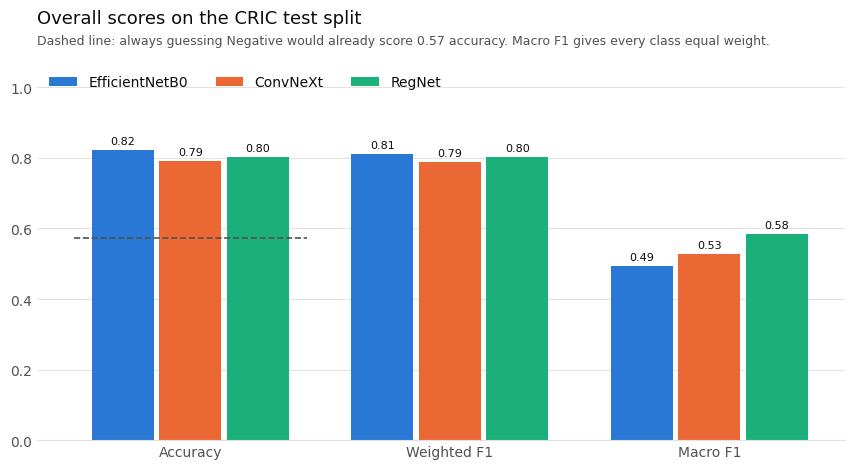

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# One fixed colour per model, used in every chart below (colour-blind safe set).
MODEL_COLORS = {"EfficientNetB0": "#2a78d6", "ConvNeXt": "#eb6834", "RegNet": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axes(ax):
    ax.set_facecolor("white")
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def grouped_bars(ax, categories, values_by_model, width=0.26, label_size=8):
    """values_by_model: {model: [value per category]}. Draws one bar per model per category."""
    x = np.arange(len(categories))
    for i, (model, vals) in enumerate(values_by_model.items()):
        offset = (i - (len(values_by_model) - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width * 0.92, color=MODEL_COLORS[model], label=model)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}", ha="center", va="bottom",
                    fontsize=label_size, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(categories, color=INK)
    ax.set_ylim(0, 1.08)
    style_axes(ax)

# ---------- Chart 1: overall scores ----------
models = list(results.keys())
metrics = [("accuracy", "Accuracy"), ("weighted_f1", "Weighted F1"), ("macro_f1", "Macro F1")]
values = {m: [results[m][k] for k, _ in metrics] for m in models}

fig, ax = plt.subplots(figsize=(9, 4.8), facecolor="white")
grouped_bars(ax, [label for _, label in metrics], values)
# Always guessing "Negative" would score this much on accuracy (about 57% of test cells are Negative).
baseline = float((np.asarray(y_true) == SHORT_NAMES.index("Negative")).mean())
ax.plot([-0.45, 0.45], [baseline, baseline], color=MUTED, linestyle="--", linewidth=1.2, zorder=3)
ax.set_title("Overall scores on the CRIC test split", loc="left", color=INK, fontsize=13, pad=26)
ax.text(0, 1.04, f"Dashed line: always guessing Negative would already score {baseline:.2f} accuracy. "
        "Macro F1 gives every class equal weight.", transform=ax.transAxes, fontsize=9, color=MUTED)
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 0.99), labelcolor=INK)
plt.tight_layout()
plt.savefig("/kaggle/working/chart_overall_scores.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## Graph 2: how many real cells of each grade each model finds

Recall per grade. The label under each grade shows how many test cells that grade has. SCC has only 34, so one cell moves its bar by about 3 points. The gaps on SCC and ASC-US are the ones worth discussing.

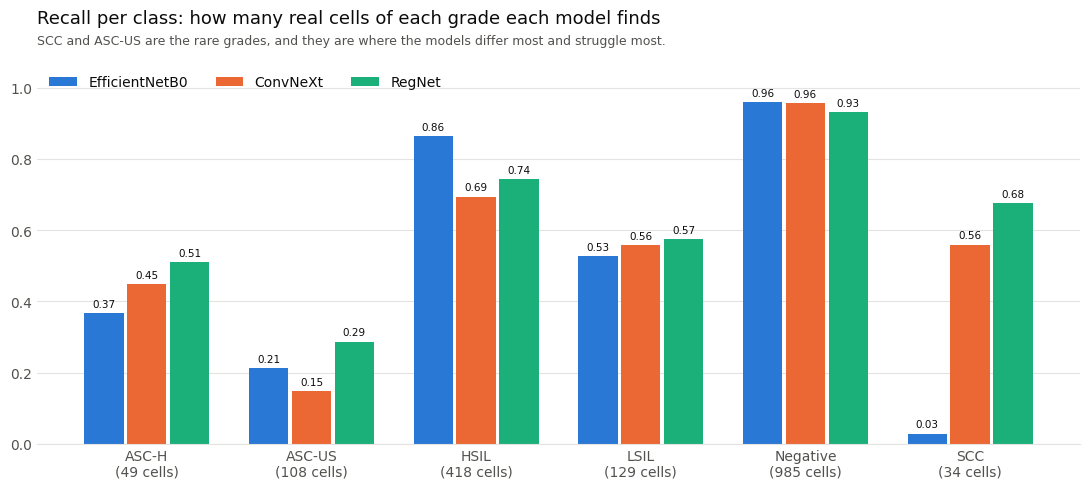

In [21]:
# ---------- Chart 2: recall per class ----------
# Recall = of the cells that truly are this class, how many did the model find.
test_counts = pd.Series(np.asarray(y_true)).map(dict(enumerate(SHORT_NAMES))).value_counts()
class_labels = [f"{c}\n({test_counts[c]} cells)" for c in SHORT_NAMES]
recalls = {m: [results[m][f"recall_{c}"] for c in SHORT_NAMES] for m in results}

fig, ax = plt.subplots(figsize=(11, 5), facecolor="white")
grouped_bars(ax, class_labels, recalls, width=0.26, label_size=7.5)
ax.set_title("Recall per class: how many real cells of each grade each model finds", loc="left",
             color=INK, fontsize=13, pad=26)
ax.text(0, 1.04, "SCC and ASC-US are the rare grades, and they are where the models differ most and struggle most.",
        transform=ax.transAxes, fontsize=9, color=MUTED)
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 0.99), labelcolor=INK)
plt.tight_layout()
plt.savefig("/kaggle/working/chart_recall_per_class.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## Graph 3: where each model's mistakes go

One panel per model. Each row is the true grade, and each box shows what share of that grade the model gave each label. The dark diagonal is correct answers. A dark box off the diagonal means a repeated mix-up, for example SCC cells called Negative.

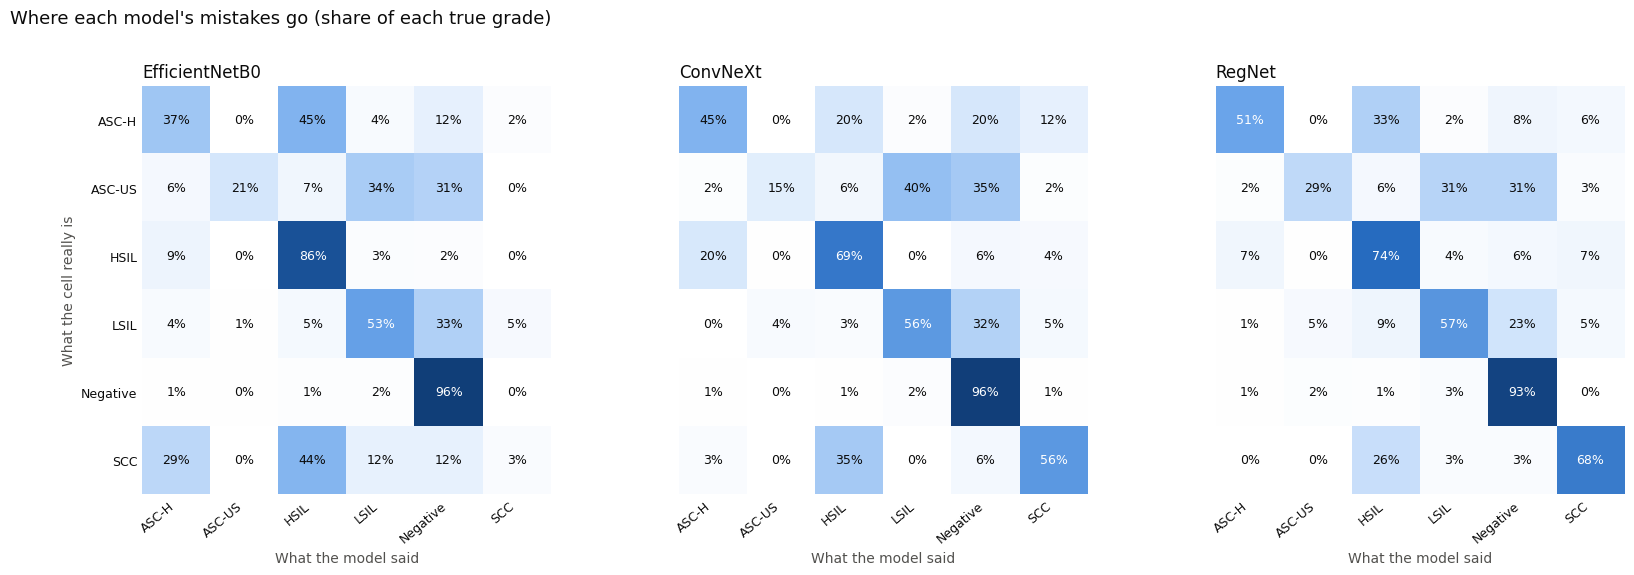

In [22]:
# ---------- Chart 3: confusion matrices, one panel per model ----------
# Each row is a TRUE grade. Each cell shows the share of that grade the model gave each label.
# The dark diagonal is "right". Anything off the diagonal is a mix-up, and the row says which one.
from sklearn.metrics import confusion_matrix
from matplotlib.colors import LinearSegmentedColormap

all_probs = {"EfficientNetB0": y_pred_probs, "ConvNeXt": y_prob_convnext, "RegNet": y_prob_regnet}
blue_ramp = LinearSegmentedColormap.from_list("blue", ["#ffffff", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
n = len(SHORT_NAMES)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), facecolor="white")
for ax, (model, probs) in zip(axes, all_probs.items()):
    counts = confusion_matrix(y_true, np.argmax(probs, axis=1), labels=range(n))
    share = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=blue_ramp, vmin=0, vmax=1)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if share[i, j] > 0.5 else INK)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(SHORT_NAMES, rotation=40, ha="right", color=INK, fontsize=9)
    ax.set_yticklabels(SHORT_NAMES if ax is axes[0] else [], color=INK, fontsize=9)
    ax.set_xlabel("What the model said", color=MUTED)
    if ax is axes[0]:
        ax.set_ylabel("What the cell really is", color=MUTED)
    ax.set_title(model, loc="left", color=INK, fontsize=12)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Where each model's mistakes go (share of each true grade)", x=0.01, ha="left",
             fontsize=13, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig("/kaggle/working/chart_confusion_matrices.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## Tables: confusion matrix counts, precision and recall, common mix-ups, agreement

The same results as the graphs, but as tables. First, a confusion matrix for each model as raw counts. Next, precision, recall and F1 per grade. Precision asks how often a model is right when it names a grade. Recall asks how many real cells of that grade it finds. Then each model's five most common mix-ups, and a count of how often the three models get the same cell right or wrong. Run the first graph cell (NEW 11) before this one, because it defines the colours and imports.

In [23]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

grades = SHORT_NAMES
y_true_arr = np.asarray(y_true)
all_probs = {"EfficientNetB0": y_pred_probs, "ConvNeXt": y_prob_convnext, "RegNet": y_prob_regnet}
all_preds = {m: np.argmax(p, axis=1) for m, p in all_probs.items()}
n_grades = len(grades)

# ---------- 1. Confusion matrix as counts ----------
for model, pred in all_preds.items():
    cm = pd.DataFrame(confusion_matrix(y_true_arr, pred, labels=range(n_grades)),
                      index=[f"really {g}" for g in grades], columns=[f"said {g}" for g in grades])
    print(f"\n{model}: each row is the real grade, each column is what the model said (counts of cells)")
    display(cm.style.background_gradient(cmap="Blues", axis=1))

# ---------- 2. Precision, recall and F1 per grade ----------
rows = []
for model, pred in all_preds.items():
    p, r, f, s = precision_recall_fscore_support(y_true_arr, pred, labels=range(n_grades), zero_division=0)
    for i, g in enumerate(grades):
        rows.append({"model": model, "grade": g, "precision": p[i], "recall": r[i], "f1": f[i]})
per_grade = pd.DataFrame(rows)
explain = {"precision": "when the model says this grade, how often it is right",
           "recall": "of the real cells of this grade, how many the model finds",
           "f1": "one number that balances the two"}
for metric in ["precision", "recall", "f1"]:
    print(f"\n{metric}: {explain[metric]}")
    table = per_grade.pivot(index="grade", columns="model", values=metric).reindex(grades)[list(all_probs)]
    display(table.round(3).style.background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1))

# ---------- 3. The most common mix-ups for each model ----------
for model, pred in all_preds.items():
    mistakes = pd.DataFrame({"really": [grades[i] for i in y_true_arr],
                             "model said": [grades[i] for i in pred]})
    mistakes = mistakes[mistakes["really"] != mistakes["model said"]]
    top = mistakes.value_counts().head(5).rename("cells").reset_index()
    top["share of that grade"] = [f"{c / (y_true_arr == grades.index(g)).sum():.0%}"
                                  for g, c in zip(top["really"], top["cells"])]
    print(f"\n{model}: its 5 most common mix-ups")
    display(top)

# ---------- 4. Do the three models agree? ----------
right = np.stack([all_preds[m] == y_true_arr for m in all_preds])      # 3 rows, one per model
n_right = right.sum(axis=0)
agree = pd.DataFrame({"test cells": [(n_right == 3).sum(), (n_right == 2).sum(), (n_right == 1).sum(), (n_right == 0).sum()]},
                     index=["all three right", "two right", "one right", "none right"])
agree["share"] = (agree["test cells"] / len(y_true_arr)).map("{:.0%}".format)
print("\nHow many models got each test cell right")
display(agree)

preds_stack = np.stack(list(all_preds.values()))
same_answer = (preds_stack == preds_stack[0]).all(axis=0)
print(f"\nAll three give the same answer on {same_answer.mean():.0%} of cells, and that shared answer is right "
      f"{right[0][same_answer].mean():.0%} of the time.")
print(f"On the other {(~same_answer).mean():.0%} they disagree. There, each model is right:")
for i, m in enumerate(all_preds):
    print(f"   {m}: {right[i][~same_answer].mean():.0%}")


EfficientNetB0: each row is the real grade, each column is what the model said (counts of cells)


,said ASC-H,said ASC-US,said HSIL,said LSIL,said Negative,said SCC
really ASC-H,18,0,22,2,6,1
really ASC-US,6,23,8,37,34,0
really HSIL,36,0,361,11,9,1
really LSIL,5,1,7,68,42,6
really Negative,6,4,13,15,946,1
really SCC,10,0,15,4,4,1



ConvNeXt: each row is the real grade, each column is what the model said (counts of cells)


,said ASC-H,said ASC-US,said HSIL,said LSIL,said Negative,said SCC
really ASC-H,22,0,10,1,10,6
really ASC-US,2,16,7,43,38,2
really HSIL,83,2,290,1,24,18
really LSIL,0,5,4,72,41,7
really Negative,6,3,6,23,942,5
really SCC,1,0,12,0,2,19



RegNet: each row is the real grade, each column is what the model said (counts of cells)


...


RegNet: its 5 most common mix-ups


,really,model said,cells,share of that grade
0,ASC-US,LSIL,33,31%
1,ASC-US,Negative,33,31%
2,HSIL,ASC-H,31,7%
3,HSIL,SCC,31,7%
4,LSIL,Negative,30,23%



How many models got each test cell right


,test cells,share
all three right,1205,70%
two right,211,12%
one right,123,7%
none right,184,11%



All three give the same answer on 75% of cells, and that shared answer is right 93% of the time.
On the other 25% they disagree. There, each model is right:
   EfficientNetB0: 50%
   ConvNeXt: 37%
   RegNet: 41%


## ROC curves: how well each model separates one grade from the rest

One panel per grade. A curve that rises quickly toward the top-left corner means the model can pick out that grade without many false alarms. The dashed diagonal is a coin flip. AUC is the area under each curve: 0.5 is a coin flip and 1.0 is perfect. AUC looks at the model's confidence scores, so it can show a model that ranks cells well even when its final answers miss. The table underneath lists the AUC numbers.

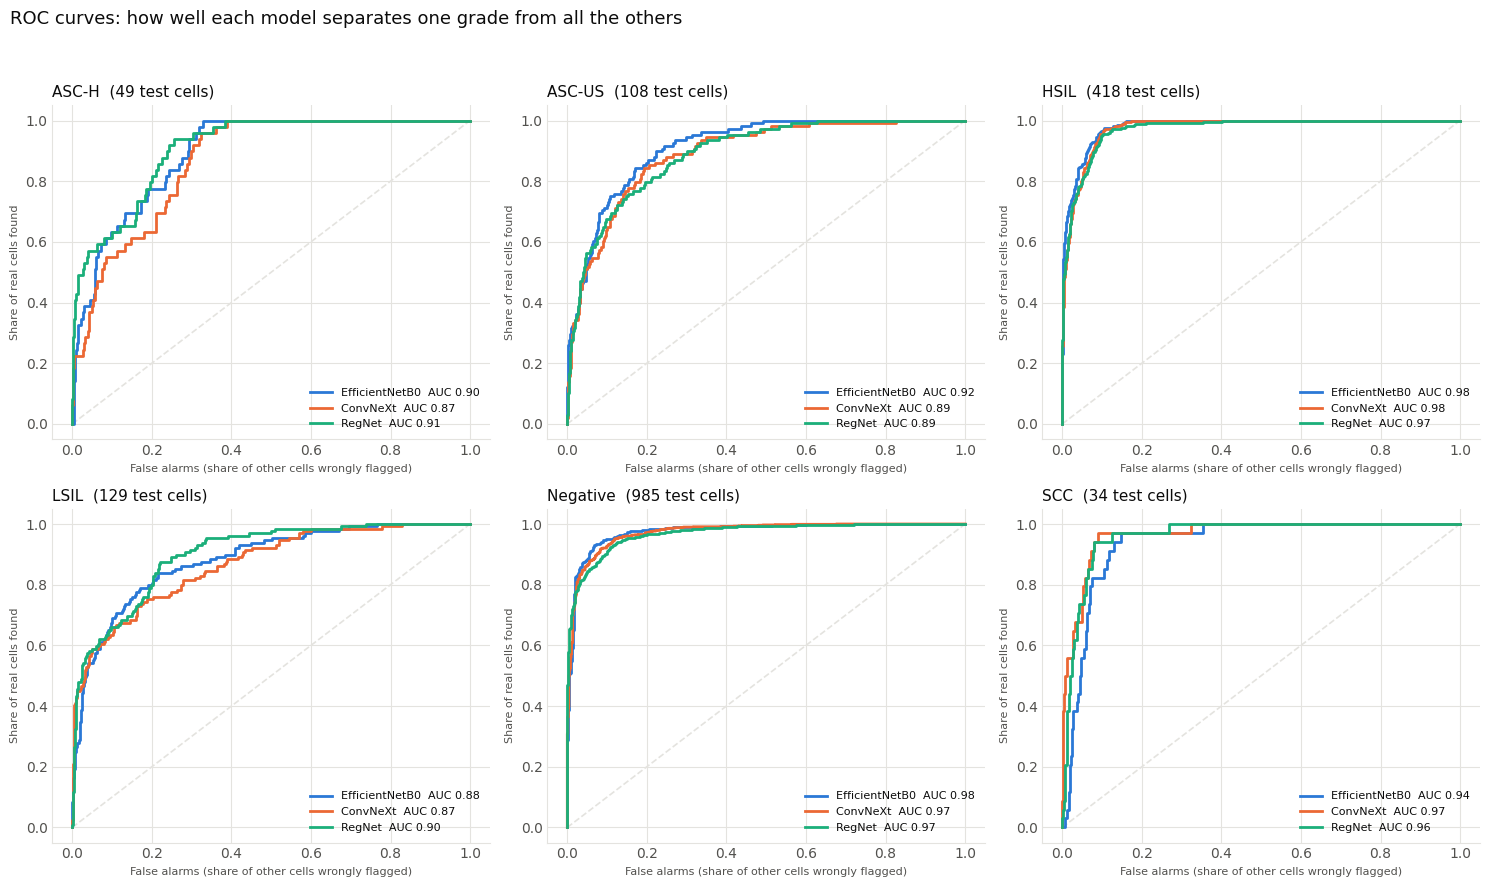

AUC per grade (0.5 = coin flip, 1.0 = perfect)


,EfficientNetB0,ConvNeXt,RegNet
ASC-H,0.895000,0.869000,0.909000
ASC-US,0.915000,0.893000,0.893000
HSIL,0.981000,0.976000,0.973000
LSIL,0.884000,0.869000,0.901000
Negative,0.976000,0.973000,0.970000
SCC,0.939000,0.967000,0.962000


In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC curve for one grade: "is it this grade or not?" Each point is one confidence cutoff.
# The higher the line bows toward the top-left corner, the better the model separates this grade from the rest.
# The dashed diagonal is a coin flip. AUC is the area under the line: 0.5 = coin flip, 1.0 = perfect.
fig, axes = plt.subplots(2, 3, figsize=(15, 9), facecolor="white")
auc_table = {}
for k, (ax, grade) in enumerate(zip(axes.ravel(), SHORT_NAMES)):
    is_grade = (np.asarray(y_true) == k)
    ax.plot([0, 1], [0, 1], color=GRID, linestyle="--", linewidth=1.2)
    for model, probs in all_probs.items():
        fpr, tpr, _ = roc_curve(is_grade, probs[:, k])
        auc = roc_auc_score(is_grade, probs[:, k])
        auc_table.setdefault(model, {})[grade] = auc
        ax.plot(fpr, tpr, color=MODEL_COLORS[model], linewidth=2, label=f"{model}  AUC {auc:.2f}")
    ax.set_title(f"{grade}  ({is_grade.sum()} test cells)", loc="left", color=INK, fontsize=11)
    ax.set_xlabel("False alarms (share of other cells wrongly flagged)", color=MUTED, fontsize=8)
    ax.set_ylabel("Share of real cells found", color=MUTED, fontsize=8)
    ax.set_facecolor("white")
    ax.grid(True, color=GRID, linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.legend(frameon=False, loc="lower right", fontsize=8, labelcolor=INK)
fig.suptitle("ROC curves: how well each model separates one grade from all the others", x=0.01, ha="left",
             fontsize=13, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig("/kaggle/working/chart_roc_curves.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

print("AUC per grade (0.5 = coin flip, 1.0 = perfect)")
display(pd.DataFrame(auc_table).reindex(SHORT_NAMES).round(3).style.background_gradient(cmap="Blues", axis=None, vmin=0.5, vmax=1))

## Random test: draw test cells and see how each model scores them

Draws cells at random from the held-out test set, which none of the models trained on. For each cell it shows the image, its real grade, and each model's confidence in all six grades. The grade a model picked is the solid bar. The real grade is bold, and the title says RIGHT or WRONG. A scoreboard below the picture counts how many each model got right. The settings at the top let you change how many cells to draw, draw only one grade such as SCC, or repeat the same draw with a seed. Run it again for a fresh draw. A handful of cells is only an illustration. The full test set tables and graphs above are what to quote.

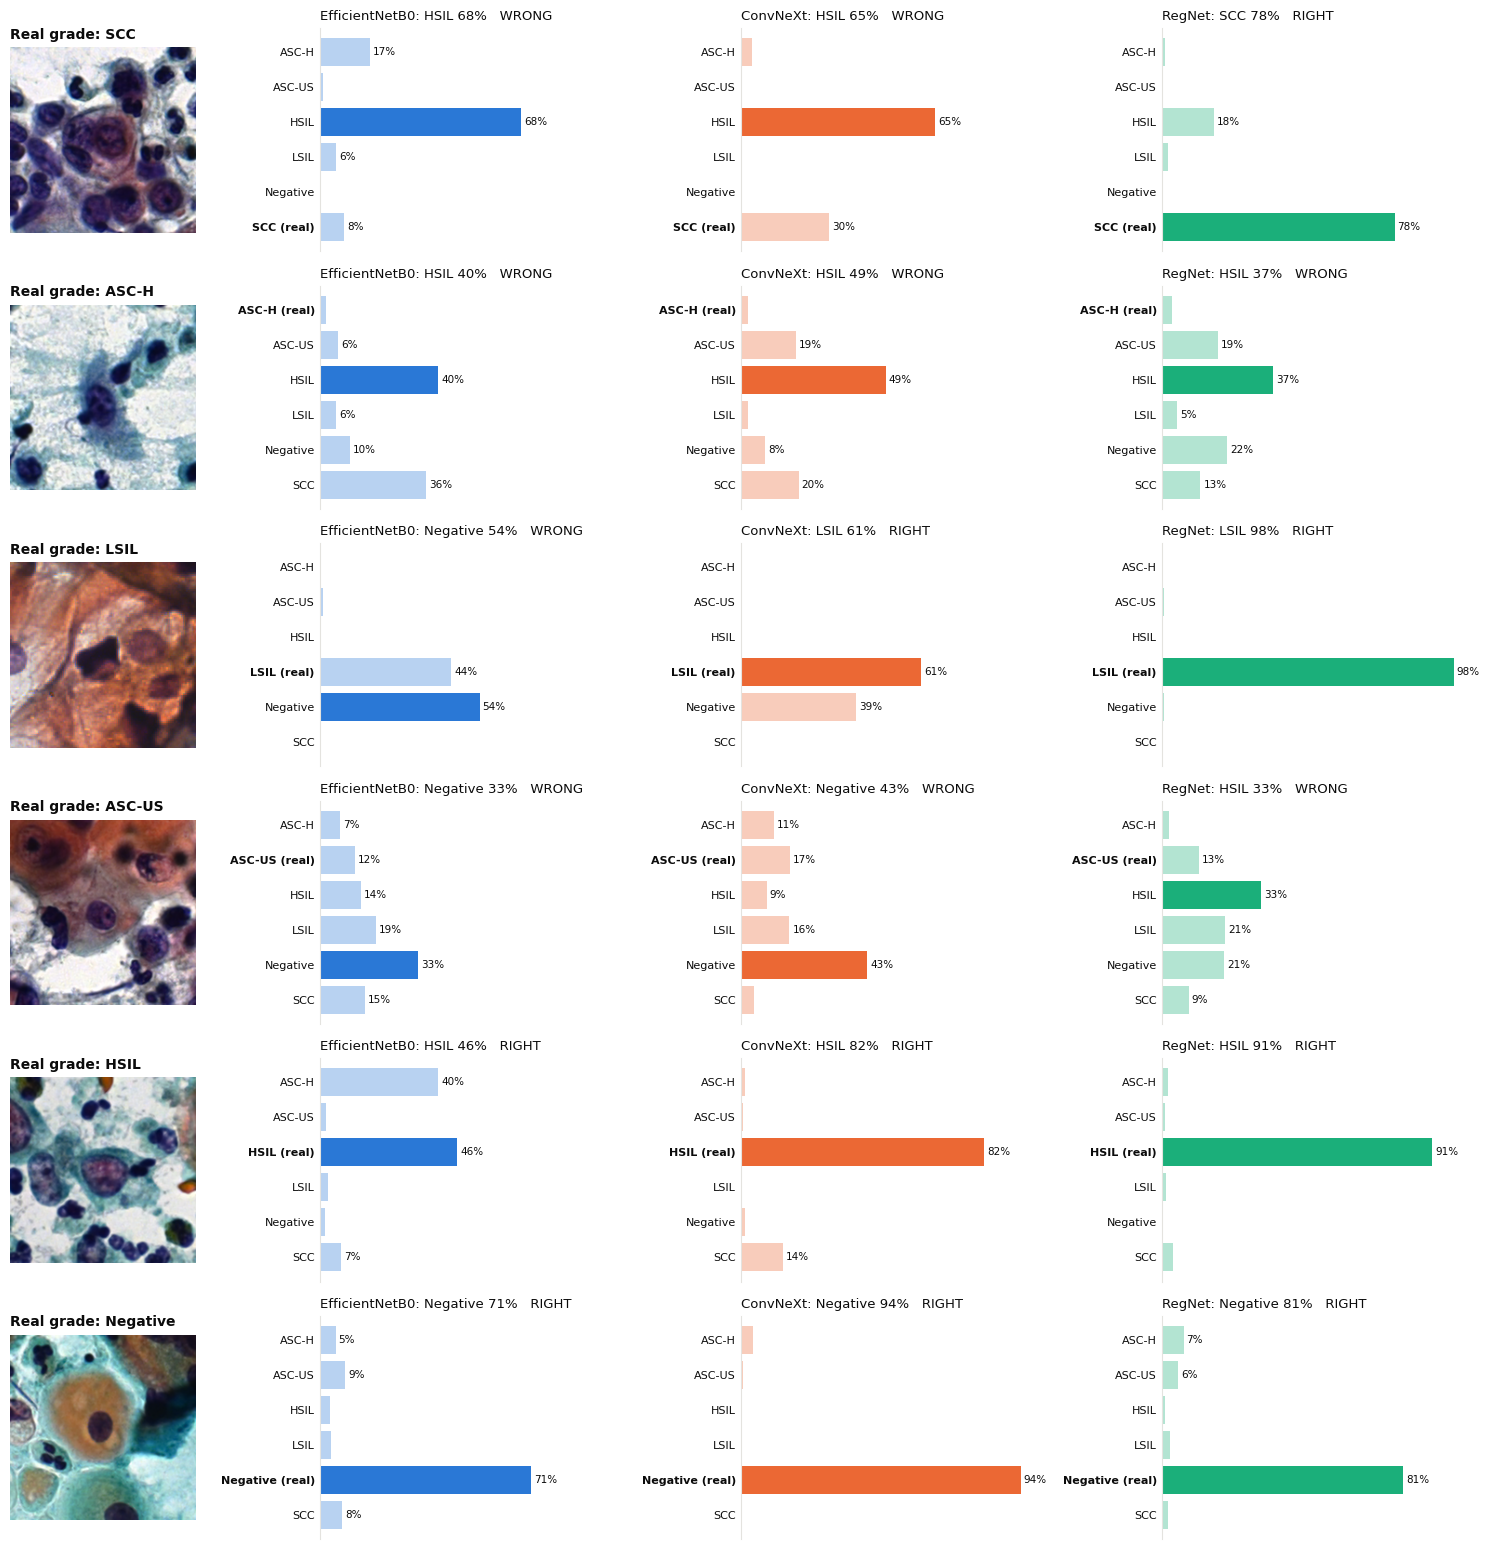

,real grade,EfficientNetB0,ConvNeXt,RegNet
0,SCC,HSIL 68% (wrong),HSIL 65% (wrong),SCC 78% (right)
1,ASC-H,HSIL 40% (wrong),HSIL 49% (wrong),HSIL 37% (wrong)
2,LSIL,Negative 54% (wrong),LSIL 61% (right),LSIL 98% (right)
3,ASC-US,Negative 33% (wrong),Negative 43% (wrong),HSIL 33% (wrong)
4,HSIL,HSIL 46% (right),HSIL 82% (right),HSIL 91% (right)
5,Negative,Negative 71% (right),Negative 94% (right),Negative 81% (right)


Right out of 6 : EfficientNetB0 2, ConvNeXt 3, RegNet 4


In [25]:
from PIL import Image

# ----- Settings: change these and run the cell again -----
N_IMAGES = 6          # how many test cells to draw
ONLY_GRADE = None     # None = a mix of grades, or a grade name such as "SCC" to draw only SCC cells
BALANCED = True       # True = spread the picks across grades. False = pure random (mostly Negative, as in the data)
SEED = None           # None = a new random draw every run. A number such as 7 repeats the same draw
# ---------------------------------------------------------

MODEL_ORDER = ["EfficientNetB0", "ConvNeXt", "RegNet"]
y_true_arr = np.asarray(y_true)
n_grades = len(SHORT_NAMES)
all_probs = {"EfficientNetB0": y_pred_probs, "ConvNeXt": y_prob_convnext, "RegNet": y_prob_regnet}

def draw_rows(items, save_as=None):
    """One row per image: the image, then each model's confidence in all six grades.
    items: list of dicts with 'path', 'true' (grade index, or None if unknown) and 'probs' ({model: 6 numbers})."""
    n = len(items)
    fig, axes = plt.subplots(n, 4, figsize=(15, 2.6 * n), facecolor="white", squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1.6, 1.6, 1.6]})
    for r, item in enumerate(items):
        truth = SHORT_NAMES[item["true"]] if item["true"] is not None else "unknown"
        axes[r, 0].imshow(Image.open(item["path"]).convert("RGB"))
        axes[r, 0].axis("off")
        axes[r, 0].set_title(f"Real grade: {truth}", loc="left", fontsize=10, color=INK, fontweight="bold")
        for c, model in enumerate(MODEL_ORDER):
            ax = axes[r, c + 1]
            p = np.asarray(item["probs"][model])
            guess = int(p.argmax())
            # The grade the model picked is drawn solid. The other grades are faded.
            colors = [MODEL_COLORS[model] if i == guess else MODEL_COLORS[model] + "55" for i in range(n_grades)]
            ax.barh(range(n_grades), p, color=colors)
            ax.set_xlim(0, 1.0)
            ax.invert_yaxis()
            ax.set_yticks(range(n_grades))
            ax.set_yticklabels([g + (" (real)" if item["true"] == i else "") for i, g in enumerate(SHORT_NAMES)],
                               fontsize=8, color=INK)
            if item["true"] is not None:
                ax.get_yticklabels()[item["true"]].set_fontweight("bold")
            verdict = "" if item["true"] is None else ("   RIGHT" if guess == item["true"] else "   WRONG")
            ax.set_title(f"{model}: {SHORT_NAMES[guess]} {p[guess]:.0%}{verdict}", loc="left", fontsize=9.5, color=INK)
            for i, v in enumerate(p):
                if v >= 0.05:
                    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=7.5, color=INK)
            ax.set_xticks([])
            ax.tick_params(length=0)
            for side in ("top", "right", "bottom"):
                ax.spines[side].set_visible(False)
            ax.spines["left"].set_color(GRID)
            ax.set_facecolor("white")
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# ---- Pick the test cells ----
test_rows = cric_test_df.reset_index(drop=True)
assert (test_rows["label"].map(cric_class_to_idx).values == y_true_arr).all(), "test rows and predictions are out of order"
rng = np.random.default_rng(SEED)

if ONLY_GRADE is not None:
    pool = np.where(y_true_arr == SHORT_NAMES.index(ONLY_GRADE))[0]
    picks = list(rng.choice(pool, size=min(N_IMAGES, len(pool)), replace=False))
elif BALANCED:
    order = rng.permutation(n_grades)
    picks = []
    for k in range(N_IMAGES):
        pool = np.setdiff1d(np.where(y_true_arr == order[k % n_grades])[0], picks)
        picks.append(int(rng.choice(pool)))
    rng.shuffle(picks)
else:
    picks = list(rng.choice(len(y_true_arr), size=N_IMAGES, replace=False))

items = [{"path": test_rows.loc[i, "filepath"], "true": int(y_true_arr[i]),
          "probs": {m: all_probs[m][i] for m in MODEL_ORDER}} for i in picks]
draw_rows(items, save_as="/kaggle/working/chart_random_test.png")

# ---- Scoreboard ----
board = pd.DataFrame({"real grade": [SHORT_NAMES[it["true"]] for it in items]})
wins = {}
for m in MODEL_ORDER:
    guesses = [int(np.argmax(it["probs"][m])) for it in items]
    wins[m] = sum(g == it["true"] for g, it in zip(guesses, items))
    board[m] = [f"{SHORT_NAMES[g]} {it['probs'][m][g]:.0%} ({'right' if g == it['true'] else 'wrong'})"
                for g, it in zip(guesses, items)]
display(board)
print("Right out of", len(items), ":", ", ".join(f"{m} {w}" for m, w in wins.items()))